# 24b. LR 강화 (2차): LR에 아미노산 치환 비율 피처 추가 → 14 섞기와 비교

## 배경
- 24 1차: LR 피처를 nonsilent + trunc로 바꾸면 섞기 CV +0.0033 (4/5). 하지만 trunc 때문에 test COAD 예측이 17.1% → 20.7%로 늘어 LB 효과 불확실 (select6과 같은 방향)
- 은지님 치환 함수(PR #29): `aa_substitution('R132H') → 'R>H'`, `aa_group_change('E545K') → 'negative>positive'`
- test 환자는 변이 수가 train의 약 2배 → **개수가 아니라 비율**로 만들면 변이 수 차이에 덜 흔들림 (11/11 회의 목표)

## 가설
- H24b: LR에 "환자의 미스센스 변이 중 각 치환 종류(또는 성질 그룹 변화)가 차지하는 비율"을 추가하면, XGB 0.7 + LR 0.3 섞기가 14보다 오른다 (trunc 없이, COAD 쏠림 없이)

## 검증 방법
- XGB는 14와 같은 모델 그대로, LR 설정(C=0.1, balanced)과 섞는 비율(0.7/0.3) 고정 → **LR 피처만** 바뀜
- 치환 비율 피처
  - **미스센스만** 사용 (침묵 R>R, 넌센스 R>\* 제외 → `mutation_type(t) == 'missense'`로 거름)
  - 환자별: (그 치환 종류의 미스센스 수) ÷ (환자의 미스센스 수) → 한 행 안에서만 계산
  - 치환 종류 선택(학습 fold에서 30명 이상에게 나온 것만)과 표준화는 **Pipeline 안에서 fold 학습 부분으로만** 계산
- 비교: 같은 fold(seed 42)에서 fold별로 14와 비교, **채택 기준 4/5 fold 이상**
- 진단(채택 판단에는 안 씀): 14와 예측이 다른 환자 비율(OOF vs test), test COAD 예측 비율
- ⚠️ XGB는 **stats 개수 버전**(14와 같은 `mutation_features`의 stats, 22a 비율 변경 전) 기준. 22a가 머지된 뒤 캐시 없이 다시 실행하면 XGB가 14와 달라져 숫자가 바뀜 (캐시: `submissions/cache24/XGB.npz` = stats 개수 버전)
- test는 예측에만 사용. 제출 파일은 설아님 Windows 데스크탑에서만 생성 (`SAVE`)


In [1]:
import sys; sys.path.append('..')
import warnings; warnings.filterwarnings('ignore')
import time, numpy as np, pandas as pd, xgboost as xgb
from collections import Counter
from pathlib import Path
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_sample_weight
from src.config import SEED, WT
from src.data import load_data, get_gene_cols
from src.features import mutation_features, mutation_type, aa_substitution, aa_group_change
from src.validation import seed_everything, encode_target, get_folds, run_cv, macro_f1, save_submission

seed_everything()
train, test, submission = load_data()
genes = get_gene_cols(train)
y, le = encode_target(train)
FOLDS = get_folds(y)
F_tr, F_te = mutation_features(train, genes), mutation_features(test, genes)

#### 치환 비율 피처 (미스센스만, 한 행 안에서 계산)

In [2]:
def substitution_ratios(df):
    """환자별 미스센스 치환 종류 비율(sub__R>H ...)과 성질 그룹 변화 비율(grp__negative>positive ...)"""
    S, G = [], []
    for row in df[genes].to_numpy():
        cs, cg, n = Counter(), Counter(), 0
        for v in row:
            if v == WT:
                continue
            for t in v.split():
                if mutation_type(t) != 'missense':     # 침묵(R>R)·넌센스(R>*) 제외
                    continue
                s, g = aa_substitution(t), aa_group_change(t)
                if s is None:
                    continue
                n += 1; cs['sub__' + s] += 1
                if g: cg['grp__' + g] += 1
        S.append({k: c / n for k, c in cs.items()}); G.append({k: c / n for k, c in cg.items()})
    mk = lambda rows: pd.DataFrame(rows, index=df.index).fillna(0).astype('float32')
    return mk(S), mk(G)

S_tr, G_tr = substitution_ratios(train)
S_te, G_te = substitution_ratios(test)
S_te, G_te = S_te.reindex(columns=S_tr.columns, fill_value=0), G_te.reindex(columns=G_tr.columns, fill_value=0)   # 열 이름만 train 기준으로 맞춤
print('치환 종류', S_tr.shape[1], '개 | 성질 그룹 변화', G_tr.shape[1], '개')
print('미스센스가 1개 이상인 환자: train %.1f%% / test %.1f%%' % ((S_tr.sum(axis=1) > 0).mean() * 100, (S_te.sum(axis=1) > 0).mean() * 100))

치환 종류 241 개 | 성질 그룹 변화 33 개
미스센스가 1개 이상인 환자: train 97.0% / test 97.6%


#### 모델: XGB(14와 동일) + LR 피처 조합
- `FrequentRatios`: 학습 fold에서 `min_count`명 미만에게만 나온 치환 열 제거 / `ScaleRatios`: 비율 열만 학습 fold 평균·표준편차로 표준화

In [3]:
CACHE = Path('../submissions/cache24'); CACHE.mkdir(parents=True, exist_ok=True)
RATIO = ('sub__', 'grp__')

class FrequentRatios(BaseEstimator, TransformerMixin):
    def __init__(self, min_count=30):
        self.min_count = min_count
    def fit(self, X, y=None):
        c = [k for k in X.columns if k.startswith(RATIO)]
        n = (X[c] > 0).sum()
        self.drop_ = n.index[n < self.min_count].tolist()
        return self
    def transform(self, X):
        return X.drop(columns=self.drop_)

class ScaleRatios(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        self.cols_ = [k for k in X.columns if k.startswith(RATIO)]
        self.sc_ = StandardScaler().fit(X[self.cols_]) if self.cols_ else None
        return self
    def transform(self, X):
        X = X.copy()
        if self.cols_: X[self.cols_] = self.sc_.transform(X[self.cols_])
        return X

class BalancedXGB(xgb.XGBClassifier):
    def fit(self, X, y, **kw):
        return super().fit(X, y, sample_weight=compute_sample_weight('balanced', y), **kw)

XGB10 = dict(n_estimators=200, learning_rate=0.1, max_depth=3, colsample_bytree=0.3,
             tree_method='hist', eval_metric='mlogloss', random_state=SEED, n_jobs=-1)
lr = lambda: make_pipeline(FrequentRatios(30), ScaleRatios(),
                           LogisticRegression(C=0.1, max_iter=3000, class_weight='balanced', random_state=SEED))

def cached(name, make, X, X_te):
    p = CACHE / f'{name}.npz'
    if p.exists():
        z = np.load(p); return z['oof'], z['test']
    t = time.time()
    r = run_cv(make, X, y, X_te, folds=FOLDS, verbose=False)
    np.savez(p, oof=r['oof_proba'], test=r['test_proba'])
    print(f'  {name}: 학습 {time.time() - t:.0f}s')
    return r['oof_proba'], r['test_proba']

EXTRA = {'sub': (S_tr, S_te), 'grp': (G_tr, G_te)}
def feats(parts, k):   # k=0 train, 1 test
    return pd.concat([(F_tr, F_te)[k][p] if p in F_tr else EXTRA[p][k] for p in parts], axis=1).astype('float32')

XGB_oof, XGB_te = cached('XGB', lambda: BalancedXGB(**XGB10), pd.concat([F_tr['any'], F_tr['stats']], axis=1), pd.concat([F_te['any'], F_te['stats']], axis=1))
LR_SETS = {   # 이름: 피처 묶음 (sub = 치환 종류 비율, grp = 성질 그룹 변화 비율)
    'any (14 기준)':            ['any'],
    'any + 치환':               ['any', 'sub'],
    'any + 성질그룹':           ['any', 'grp'],
    'any + 치환 + 성질그룹':    ['any', 'sub', 'grp'],
    'nonsilent + trunc + 치환': ['nonsilent', 'trunc', 'sub'],
}
LR_oof, LR_te = {}, {}
for name, parts in LR_SETS.items():
    key = 'LR_any' if parts == ['any'] else 'LRb_' + '_'.join(parts)
    LR_oof[name], LR_te[name] = cached(key, lr, feats(parts, 0), feats(parts, 1))
print('완료')

  LRb_any_sub: 학습 20s


  LRb_any_grp: 학습 14s


  LRb_any_sub_grp: 학습 20s


  LRb_nonsilent_trunc_sub: 학습 35s
완료


#### 비교: fold별, 14 대비

In [4]:
fold_scores = lambda P: np.array([macro_f1(y[va], P[va].argmax(1)) for _, va in FOLDS])
blend = lambda name, test=False: 0.7 * (XGB_te if test else XGB_oof) + 0.3 * (LR_te[name] if test else LR_oof[name])
BASE = 'any (14 기준)'
base = fold_scores(blend(BASE)); o14, t14 = blend(BASE), blend(BASE, True)
rows = []
for name in LR_SETS:
    s = fold_scores(blend(name)); d = s - base; o, t = blend(name), blend(name, True)
    rows.append({'LR 피처': name, 'LR 단독 CV': fold_scores(LR_oof[name]).mean(), '섞기 CV': s.mean(), '섞기 std': s.std(),
                 '14 대비': d.mean(), '14보다 높은 fold': f'{(d > 0).sum()}/5',
                 '채택': '✅' if name != BASE and (d > 0).sum() >= 4 else '',
                 '14와 다른 환자 OOF %': (o.argmax(1) != o14.argmax(1)).mean() * 100,
                 '14와 다른 환자 test %': (t.argmax(1) != t14.argmax(1)).mean() * 100,
                 'test COAD %': (le.inverse_transform(t.argmax(1)) == 'COAD').mean() * 100})
res = pd.DataFrame(rows).set_index('LR 피처')
print('14 섞기 fold별', base.round(4))
for name in LR_SETS:
    if name != BASE: print(f'{name:26s} fold별 차이', (fold_scores(blend(name)) - base).round(4))
res.round(4)

14 섞기 fold별 [0.4119 0.423  0.4378 0.4098 0.4261]
any + 치환                   fold별 차이 [0.021  0.0115 0.0213 0.0098 0.0083]
any + 성질그룹                 fold별 차이 [0.0116 0.0031 0.0051 0.0045 0.0073]
any + 치환 + 성질그룹            fold별 차이 [0.0213 0.0129 0.0209 0.0116 0.0064]
nonsilent + trunc + 치환     fold별 차이 [0.0196 0.006  0.028  0.0111 0.0132]


,LR 단독 CV,섞기 CV,섞기 std,14 대비,14보다 높은 fold,채택,14와 다른 환자 OOF %,14와 다른 환자 test %,test COAD %
LR 피처,,,,,,,,,
any (14 기준),0.3818,0.4217,0.0102,0.0000,0/5,,0.0000,0.0000,17.1249
any + 치환,0.3528,0.4361,0.0128,0.0144,5/5,✅,17.5133,16.3394,16.0251
any + 성질그룹,0.3895,0.4281,0.0096,0.0063,5/5,✅,8.3051,8.1697,16.5750
any + 치환 + 성질그룹,0.3525,0.4364,0.0122,0.0146,5/5,✅,17.8520,16.9678,15.9073
nonsilent + trunc + 치환,0.3485,0.4373,0.0154,0.0156,5/5,✅,17.6101,17.5177,19.3244


#### 진단: test 예측 분포 (채택 판단에는 사용하지 않음)

In [5]:
dist = lambda p: pd.Series(le.inverse_transform(p.argmax(1))).value_counts(normalize=True) * 100
tab = pd.DataFrame({'train': train.SUBCLASS.value_counts(normalize=True) * 100, '14': dist(t14),
                    **{n: dist(blend(n, True)) for n in LR_SETS if n != BASE}}).fillna(0)
tab.sort_values('14', ascending=False).round(1).head(12)

,train,14,any + 치환,any + 성질그룹,any + 치환 + 성질그룹,nonsilent + trunc + 치환
COAD,3.6,17.1,16.0,16.6,15.9,19.3
STES,6.1,11.7,13.7,12.0,13.8,11.0
OV,4.1,5.5,5.1,5.5,5.3,5.1
TGCT,2.0,5.0,3.6,4.6,3.6,3.7
BRCA,12.7,4.8,5.5,4.8,5.5,5.3
KIPAN,8.3,4.1,5.8,4.9,5.8,5.3
PRAD,4.3,3.8,3.1,3.4,3.1,3.2
LUSC,2.9,3.7,3.4,3.8,3.5,3.4
PCPG,2.4,3.7,3.1,3.7,3.1,3.2
UCEC,3.2,3.6,3.5,3.5,3.5,3.3


#### 그래프 (슬라이드용)

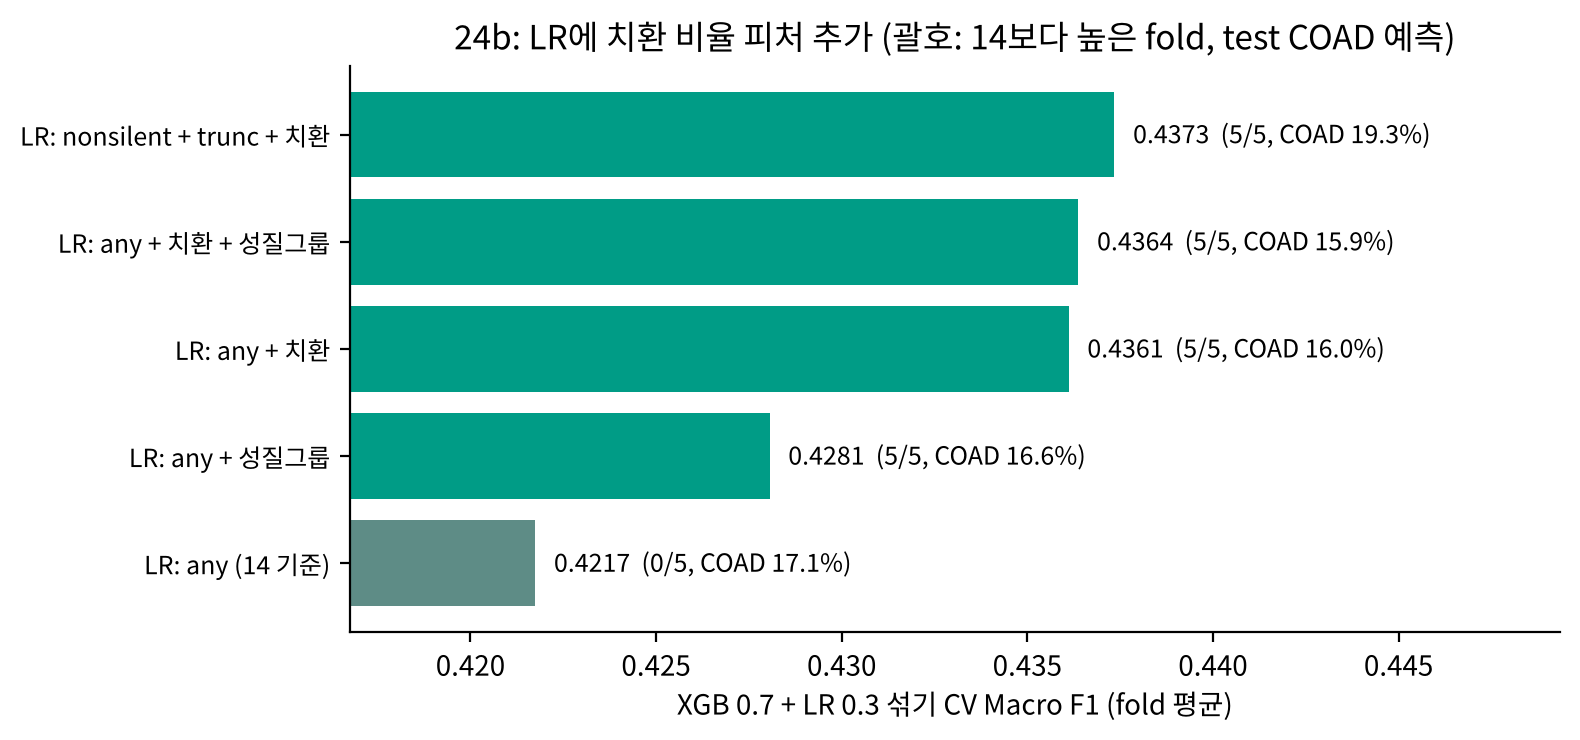

In [6]:
import matplotlib.pyplot as plt
from matplotlib import font_manager
_have = {f.name for f in font_manager.fontManager.ttflist}
plt.rcParams['font.family'] = next((f for f in ['Malgun Gothic', 'AppleGothic', 'NanumGothic', 'Noto Sans CJK KR'] if f in _have), 'DejaVu Sans')
plt.rcParams['axes.unicode_minus'] = False
order = res.sort_values('섞기 CV').index
fig, ax = plt.subplots(figsize=(8, 3.8))
cols = ['#5E8C86' if n == BASE else ('#009C86' if res.loc[n, '채택'] else '#7FCFC3') for n in order]
ax.barh(range(len(order)), res.loc[order, '섞기 CV'], color=cols)
for i, n in enumerate(order):
    ax.text(res.loc[n, '섞기 CV'] + 0.0005, i, f"{res.loc[n, '섞기 CV']:.4f}  ({res.loc[n, '14보다 높은 fold']}, COAD {res.loc[n, 'test COAD %']:.1f}%)", va='center', fontsize=9)
ax.set_yticks(range(len(order)), [f'LR: {n}' for n in order], fontsize=9)
ax.set_xlim(res['섞기 CV'].min() - 0.005, res['섞기 CV'].max() + 0.012)
ax.set_xlabel('XGB 0.7 + LR 0.3 섞기 CV Macro F1 (fold 평균)'); ax.set_title('24b: LR에 치환 비율 피처 추가 (괄호: 14보다 높은 fold, test COAD 예측)')
for s in ['top', 'right']: ax.spines[s].set_visible(False)
plt.tight_layout(); plt.savefig('../submissions/24b_lr_substitution.png', dpi=150); plt.show()

#### 제출 파일 (채택된 조합만, 설아님 Windows 데스크탑에서 `SAVE = True`)

In [7]:
SAVE = False   # 팀 규칙: 제출 파일은 Windows 데스크탑에서만 생성
TAG = {'any + 치환': 'any_sub', 'any + 성질그룹': 'any_grp', 'any + 치환 + 성질그룹': 'any_sub_grp', 'nonsilent + trunc + 치환': 'nonsilent_trunc_sub'}
adopted = [n for n in LR_SETS if res.loc[n, '채택']]
print('채택:', adopted or '없음')
if SAVE:
    for name in adopted:
        print('저장:', save_submission(submission, blend(name, True), le, name=f'blend_XGB0.7_LR-{TAG[name]}0.3', cv_score=res.loc[name, '섞기 CV']))

채택: ['any + 치환', 'any + 성질그룹', 'any + 치환 + 성질그룹', 'nonsilent + trunc + 치환']


## 결과
| LR 피처 (XGB 0.7 + LR 0.3) | LR 단독 CV | 섞기 CV | 14 대비 | 14보다 높은 fold | 14와 다른 환자 test (OOF) | test COAD % |
| :-- | :-: | :-: | :-: | :-: | :-: | :-: |
| any (14 기준) | 0.3818 | 0.4217 | — | — | — | 17.1 |
| **any + 치환** | 0.3528 | **0.4361** | **+0.0144** | **5/5** | 16.3% (17.5%) | 16.0 |
| any + 성질그룹 | 0.3895 | 0.4281 | +0.0063 | 5/5 | 8.2% (8.3%) | 16.6 |
| any + 치환 + 성질그룹 | 0.3525 | 0.4364 | +0.0146 | 5/5 | 17.0% (17.9%) | 15.9 |
| nonsilent + trunc + 치환 | 0.3485 | 0.4373 | +0.0156 | 5/5 | 17.5% (17.6%) | 19.3 |

- CV는 fold 평균, 이 실행 환경(Linux) XGB 기준 (14 섞기 0.4217은 16·24 1차와 같은 기준)
- ⚠️ **실행 환경별 차이** (같은 코드, 같은 seed): any + 치환 섞기 CV
  | 실행 환경 | 섞기 CV | 비고 |
  | :-- | :-: | :-- |
  | Linux (이 노트북 출력) | 0.4361 | 위 표 기준 |
  | Windows 데스크탑 (제출 파일 생성) | 0.4391 | 제출 파일명 `1112_blend_XGB0.7_LR-any_sub0.3_0.439.csv` |
  - LR 단독 CV는 두 환경에서 거의 같음 → 차이는 XGB 실행 환경 차이 (17 리뷰에서 확인한 ±0.004 범위)
- 4개 조합 모두 5개 fold 전부에서 14보다 높음. fold별 차이도 가장 작은 fold가 +0.006~0.010 (any + 치환: +0.008 ~ +0.021)
- **치환 종류 비율이 핵심**: any + 치환 +0.0144. 성질 그룹만 넣으면 +0.0063이고, 치환에 성질 그룹을 더해도 +0.0002뿐 → 성질 그룹 정보는 치환 종류에 이미 들어 있음
- LR 단독 CV는 오히려 내려감 (0.3818 → 0.3528). 그런데 섞기는 크게 오름 → 치환 비율 LR은 XGB가 못 보는 정보를 줘서 섞기 재료로 좋음 (1차 nonsilent + trunc와 같은 패턴)
- trunc를 같이 넣으면 CV는 +0.0012 더 오르지만 test COAD 예측이 19.3%로 늘어남 (1차와 같은 방향)

**진단 (채택 판단에는 안 씀)**
- 14와 예측이 다른 환자 비율이 **OOF와 test에서 거의 같음** (any + 치환: 17.5% vs 16.3%) → test에서만 다르게 움직이지 않음. 1차 trunc 조합은 test에서 2배였음 (3.5% vs 7.2%)
- any + 치환의 test COAD 예측 16.0% → 14(17.1%)와 비슷, 20번 APC 대략치(약 17%) 근처
- 미스센스가 1개 이상인 환자 비율: train 97.0% / test 97.6% → 비율 피처가 정의되는 범위가 같음

## LB 결과 (11/12 제출)
| 제출 | LB | 14 대비 |
| :-- | :-: | :-: |
| 14 섞기: XGB 0.7 + LR(any) 0.3 | 0.3247 | — |
| **24b: XGB 0.7 + LR(any + 치환) 0.3** | **0.3324** | **+0.0077** |
| C: 22b XGB 0.7 + LR(any) 0.3 (22) | 0.3650 | +0.0403 |
| C + XGB 시드 5개 평균 | 0.3660 | +0.0413 |

- 24b는 LB에서도 14보다 오름 → "피처 추가로 오른 CV가 LB로 이어진" 사례 (개수가 아닌 비율 피처)
- 같은 치환 비율을 XGB에 넣은 C가 훨씬 높음 → 최종 후보는 C 계열
- C에 24b의 LR(any + 치환)을 섞는 조합은 C보다 CV −0.0078 (1/5 fold)로 기각 (설아님 확인) → XGB와 LR이 같은 치환 정보를 보면 섞기 이득이 사라짐

## 결론
- **H24b 채택 (CV·LB 모두 14보다 상승)**: LR에 미스센스 치환 종류 비율을 추가하면 14 섞기 대비 +0.0144, 5/5 fold
- **제출 후보 제안: XGB 0.7 + LR(any + 치환) 0.3**
  - 가장 단순한 조합이고, COAD 쏠림이 없고, OOF와 test에서 움직임이 비슷함
  - trunc를 더한 조합은 CV가 조금 더 높지만 COAD를 늘려서 후순위
- ⚠️ 주의: 지금까지 "피처 추가로 오른 CV는 LB로 안 넘어감"(07 F, 11, select6) 이력이 있음. 이번에는 개수가 아닌 **비율**이라 test의 변이 수 2배 차이에 덜 흔들릴 것으로 기대하지만, 최종 확인은 LB
- 은지님 22b(XGB에 치환 비율)와 같은 피처라, 22b 결과와 함께 보고 12일 제출 순서를 정하면 좋음
- 제출 파일은 설아님 Windows 데스크탑에서 `SAVE = True`로 생성 (XGB 환경 차이로 숫자가 조금 달라질 수 있음, LR 단독 CV는 같아야 함)
